# DFUTissue: WoundFormer vs DFUTissueSegNet vs WoundFormer-GL — single seed

Trains each model once (one seed) on the official DFUTissue split (78 train / 16 val / 16 test, Original crops) with the WoundFormer paper's protocol (224², Adam 1e-4, batch 8, cross-entropy, ReduceLROnPlateau 0.1/5 and early stopping 15 on the validation loss, checkpoint = best validation mIoU), then evaluates on the test set, compares with the paper's Table 3 and draws curves and qualitative results.

| setting | meaning |
|---|---|
| `DATA_ROOT` | the DFUTissue folder that contains `Labeled/` (from github.com/uwm-bigdata/DFUTissueSegNet, folder `DFUTissue`) |
| `MODELS` | any of `woundformer`, `dfutissuesegnet`, `woundformer_gl` |
| `SETTINGS` | `noaug` = without augmentation, `aug` = DFUTissueSegNet augmentation |
| `EPOCHS` | 200 = the paper's protocol (early stopping ends runs much earlier); 1–2 = quick check that everything runs |
| `RETRAIN` | `False`: finished runs (with `results.json`) are skipped, so the notebook can be re-run / resumed |
| `KEEP_WEIGHTS` | keep `best.pth` (~330 MB for WoundFormer / -GL, ~190 MB for DFUTissueSegNet) |

Approximate time per run on an 8 GB RTX 4060: WoundFormer 2–3 min, DFUTissueSegNet 2–4 min, WoundFormer-GL 15–25 min
(it processes the full image plus four tiles; activation checkpointing is switched on automatically to fit 8 GB).

In [1]:
# ---- settings ----------------------------------------------------------------------------------
import os
DATA_ROOT = os.environ.get("WOUNDSEG_DATA", r"/home/yash/Desktop/Aizhan/WoundSegmentation/DFUTissue")   # folder that contains Labeled/
SEED = int(os.environ.get("WOUNDSEG_SEED", 0))
MODELS = ["woundformer", "dfutissuesegnet", "woundformer_gl"]
SETTINGS = os.environ.get("WOUNDSEG_SETTINGS", "noaug aug").split()   # "noaug" and/or "aug"
EPOCHS = int(os.environ.get("WOUNDSEG_EPOCHS", 200))
RUNS_ROOT = os.environ.get("WOUNDSEG_RUNS", "runs")
RETRAIN = False
KEEP_WEIGHTS = True

## Environment and data check

In [2]:
import os, sys, subprocess, time
from pathlib import Path

# repository root (this notebook lives in <repo>/notebooks)
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(REPO)
sys.path.insert(0, str(REPO))

import torch
from IPython.display import Markdown, display
print("repo   :", REPO)
print("torch  :", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print("GPU    :", p.name, f"{p.total_memory / 2**30:.1f} GB")

# dataset check
lab = Path(DATA_ROOT) / "Labeled"
for f in ["labeled_train_names.txt", "labeled_val_names.txt", "test_names.txt"]:
    assert (lab / f).exists(), f"missing {lab / f}: set DATA_ROOT to the DFUTissue folder that contains Labeled/"
for sub in ["Images/TrainVal", "Images/Test", "Annotations/TrainVal", "Annotations/Test"]:
    n = len(list((lab / "Original" / sub).glob("*.png")))
    print(f"Original/{sub:22s} {n} files")


repo   : /home/yash/Downloads/WoundTissueSeg_code/WoundTissueSeg
torch  : 2.14.1+cu130 | CUDA available: False
Original/Images/TrainVal        93 files
Original/Images/Test            16 files
Original/Annotations/TrainVal   93 files
Original/Annotations/Test       16 files


## Train, validate and test

Each run writes `runs/<model>_<setting>_s<seed>/` with `log.csv`, `results.json`, `best.pth` and the test predictions.

In [3]:
def run_dir(model, setting, seed):
    return Path(RUNS_ROOT) / f"{model}_{setting}_s{seed}"


def train(model, setting, seed):
    """Runs train.py in a separate process (clean GPU memory per run) and streams its output."""
    out = run_dir(model, setting, seed)
    if (out / "results.json").exists() and not RETRAIN:
        print(f"[skip] {out} already finished (set RETRAIN = True to train again)")
        return
    cmd = [sys.executable, "-W", "ignore", "train.py", "--model", model, "--data-root", str(DATA_ROOT),
           "--seed", str(seed), "--epochs", str(EPOCHS), "--runs-root", str(RUNS_ROOT)]
    if setting == "aug":
        cmd.append("--aug")
    if not KEEP_WEIGHTS:
        cmd.append("--no-ckpt")
    print(f"\n=== {model} | {setting} | seed {seed} ===", flush=True)
    t0 = time.time()
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in proc.stdout:
        print(line, end="", flush=True)
    if proc.wait() != 0:
        raise RuntimeError(f"training failed: {' '.join(cmd)}")
    print(f"[done] {out}  ({(time.time() - t0) / 60:.1f} min)")


In [4]:
for setting in SETTINGS:
    for model in MODELS:
        train(model, setting, SEED)

[skip] runs/woundformer_noaug_s0 already finished (set RETRAIN = True to train again)
[skip] runs/dfutissuesegnet_noaug_s0 already finished (set RETRAIN = True to train again)
[skip] runs/woundformer_gl_noaug_s0 already finished (set RETRAIN = True to train again)
[skip] runs/woundformer_aug_s0 already finished (set RETRAIN = True to train again)
[skip] runs/dfutissuesegnet_aug_s0 already finished (set RETRAIN = True to train again)
[skip] runs/woundformer_gl_aug_s0 already finished (set RETRAIN = True to train again)


## Results vs the paper (test Dice %, dataset-level)

In [5]:
from compare_with_paper import compare
display(Markdown(compare(RUNS_ROOT, MODELS, SETTINGS, [SEED])))

Test Dice (%), dataset-level, test_224. Paper rows = single runs of Table 3; best run = seed with the highest Avg (4); mean ± SD over the seeds found.

### DFUTissue, without augmentation

| Model | runs | Gran | Fibrin | Callus | Back | Avg (4) | Tissue (3) | FG |
|---|---|---|---|---|---|---|---|---|
| WoundFormer (paper) | 1 | 82.45 | 69.32 | 86.71 | 74.88 | 78.34 | 79.49 | – |
| DFUTissueSegNet (paper) | 1 | 90.75 | 68.40 | 82.31 | 76.50 | 79.49 | 80.49 | – |
| WoundFormer (ours), best run (seed 0) | 1 | 91.33 | 81.10 | 72.42 | 94.07 | 84.73 | 81.62 | 86.29 |
| DFUTissueSegNet (ours), best run (seed 0) | 1 | 86.26 | 63.85 | 74.99 | 93.78 | 79.72 | 75.03 | 86.15 |
| WoundFormer-GL (ours), best run (seed 0) | 1 | 92.84 | 64.25 | 77.67 | 94.80 | 82.39 | 78.25 | 88.64 |

Seed-paired difference vs your WoundFormer (without augmentation): mean Δ (seeds improved)

| Model | shared seeds | Gran | Fibrin | Callus | Back | Avg (4) | Tissue (3) | FG |
|---|---|---|---|---|---|---|---|---|
| DFUTissueSegNet | 0 | -5.07 (0/1) | -17.25 (0/1) | +2.56 (1/1) | -0.29 (0/1) | -5.01 (0/1) | -6.59 (0/1) | -0.14 (0/1) |
| WoundFormer-GL | 0 | +1.51 (1/1) | -16.86 (0/1) | +5.25 (1/1) | +0.73 (1/1) | -2.34 (0/1) | -3.37 (0/1) | +2.35 (1/1) |

WoundFormer: your mean minus the paper's run: Gran +8.88, Fibrin +11.78, Callus -14.29, Back +19.19, Avg (4) +6.39, Tissue (3) +2.13

DFUTissueSegNet: your mean minus the paper's run: Gran -4.49, Fibrin -4.55, Callus -7.32, Back +17.28, Avg (4) +0.23, Tissue (3) -5.45

### DFUTissue, with augmentation

| Model | runs | Gran | Fibrin | Callus | Back | Avg (4) | Tissue (3) | FG |
|---|---|---|---|---|---|---|---|---|
| WoundFormer (paper) | 1 | 88.27 | 70.75 | 87.42 | 95.13 | 85.40 | 82.15 | – |
| DFUTissueSegNet (paper) | 1 | 91.99 | 74.52 | 85.91 | 95.90 | 87.08 | 84.14 | – |
| WoundFormer (ours), best run (seed 0) | 1 | 92.81 | 84.88 | 75.70 | 94.49 | 86.97 | 84.46 | 87.77 |
| DFUTissueSegNet (ours), best run (seed 0) | 1 | 91.19 | 74.63 | 76.94 | 94.45 | 84.30 | 80.92 | 87.88 |
| WoundFormer-GL (ours), best run (seed 0) | 1 | 93.37 | 83.67 | 75.89 | 94.36 | 86.82 | 84.31 | 87.75 |

Seed-paired difference vs your WoundFormer (with augmentation): mean Δ (seeds improved)

| Model | shared seeds | Gran | Fibrin | Callus | Back | Avg (4) | Tissue (3) | FG |
|---|---|---|---|---|---|---|---|---|
| DFUTissueSegNet | 0 | -1.62 (0/1) | -10.24 (0/1) | +1.24 (1/1) | -0.04 (0/1) | -2.66 (0/1) | -3.54 (0/1) | +0.10 (1/1) |
| WoundFormer-GL | 0 | +0.56 (1/1) | -1.20 (0/1) | +0.19 (1/1) | -0.13 (0/1) | -0.15 (0/1) | -0.15 (0/1) | -0.02 (0/1) |

WoundFormer: your mean minus the paper's run: Gran +4.54, Fibrin +14.13, Callus -11.72, Back -0.64, Avg (4) +1.57, Tissue (3) +2.32

DFUTissueSegNet: your mean minus the paper's run: Gran -0.80, Fibrin +0.11, Callus -8.97, Back -1.45, Avg (4) -2.78, Tissue (3) -3.22


In [6]:
import json
lines = ["| setting | model | params (M) | best epoch | epochs run | train time (min) | val Tissue (3) | test Tissue (3) | test Avg (4) |",
         "|---|---|---|---|---|---|---|---|---|"]
for setting in SETTINGS:
    for model in MODELS:
        f = run_dir(model, setting, SEED) / "results.json"
        if f.exists():
            R = json.load(open(f))
            lines.append(f"| {setting} | {model} | {R['params'] / 1e6:.2f} | {R['best_epoch']} | {R['epochs_run']} | "
                         f"{R['train_time_s'] / 60:.1f} | {100 * R['val_224']['dataset']['Tissue']:.2f} | "
                         f"{100 * R['test_224']['dataset']['Tissue']:.2f} | {100 * R['test_224']['dataset']['Avg']:.2f} |")
display(Markdown("\n".join(lines)))


| setting | model | params (M) | best epoch | epochs run | train time (min) | val Tissue (3) | test Tissue (3) | test Avg (4) |
|---|---|---|---|---|---|---|---|---|
| noaug | woundformer | 81.82 | 15 | 21 | 0.8 | 61.59 | 81.62 | 84.73 |
| noaug | dfutissuesegnet | 47.58 | 36 | 51 | 0.9 | 56.91 | 75.03 | 79.72 |
| noaug | woundformer_gl | 82.97 | 12 | 23 | 1.5 | 59.43 | 78.25 | 82.39 |
| aug | woundformer | 81.82 | 35 | 39 | 1.2 | 61.53 | 84.46 | 86.97 |
| aug | dfutissuesegnet | 47.58 | 39 | 51 | 1.0 | 62.15 | 80.92 | 84.30 |
| aug | woundformer_gl | 82.97 | 21 | 27 | 1.9 | 65.16 | 84.31 | 86.82 |

## Training curves

saved figures/curves_noaug_s0.png


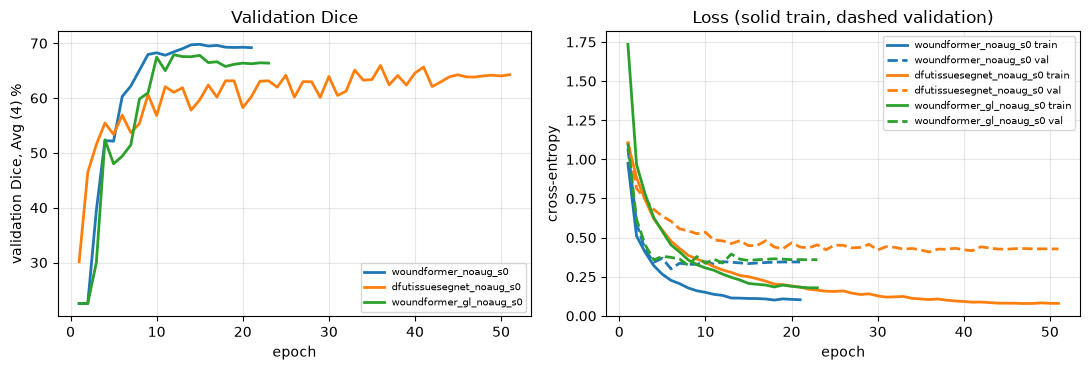

saved figures/curves_aug_s0.png


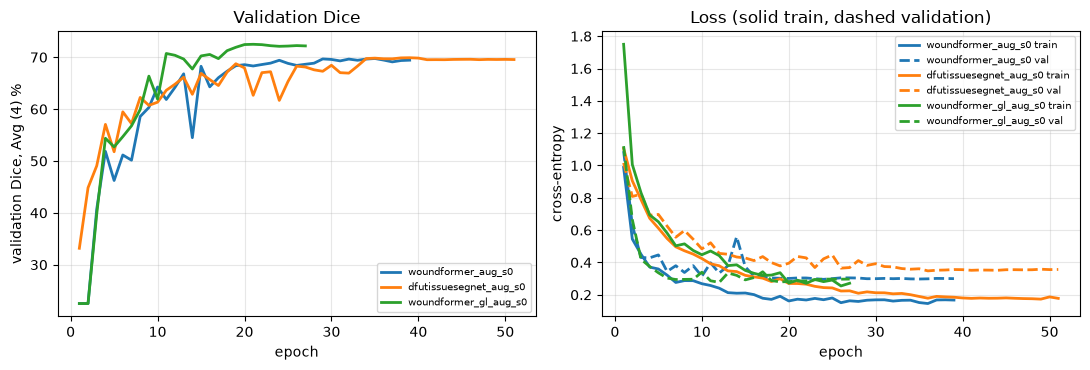

In [7]:
%matplotlib inline
import matplotlib.pyplot as plt
import visualize
for setting in SETTINGS:
    runs = [str(run_dir(m, setting, SEED)) for m in MODELS if (run_dir(m, setting, SEED) / 'log.csv').exists()]
    if runs:
        fig = visualize.curves(runs, [Path(r).name for r in runs], out=f'figures/curves_{setting}_s{SEED}.png')
        plt.show()

## Qualitative results (test images)

`IMAGES` = test image names to show (default: three images with fibrin and one hard callus case).

saved figures/qualitative_noaug_s0.png


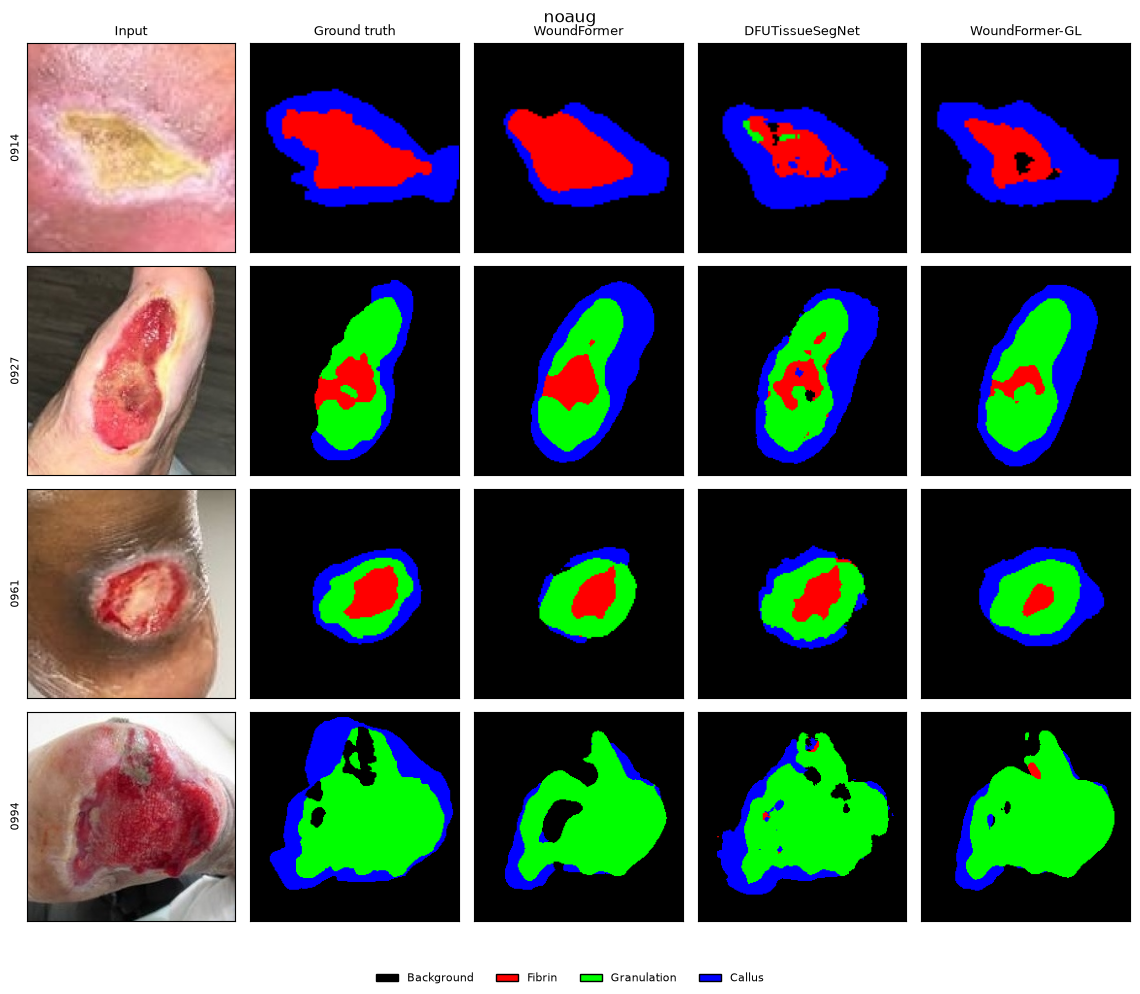

saved figures/qualitative_aug_s0.png


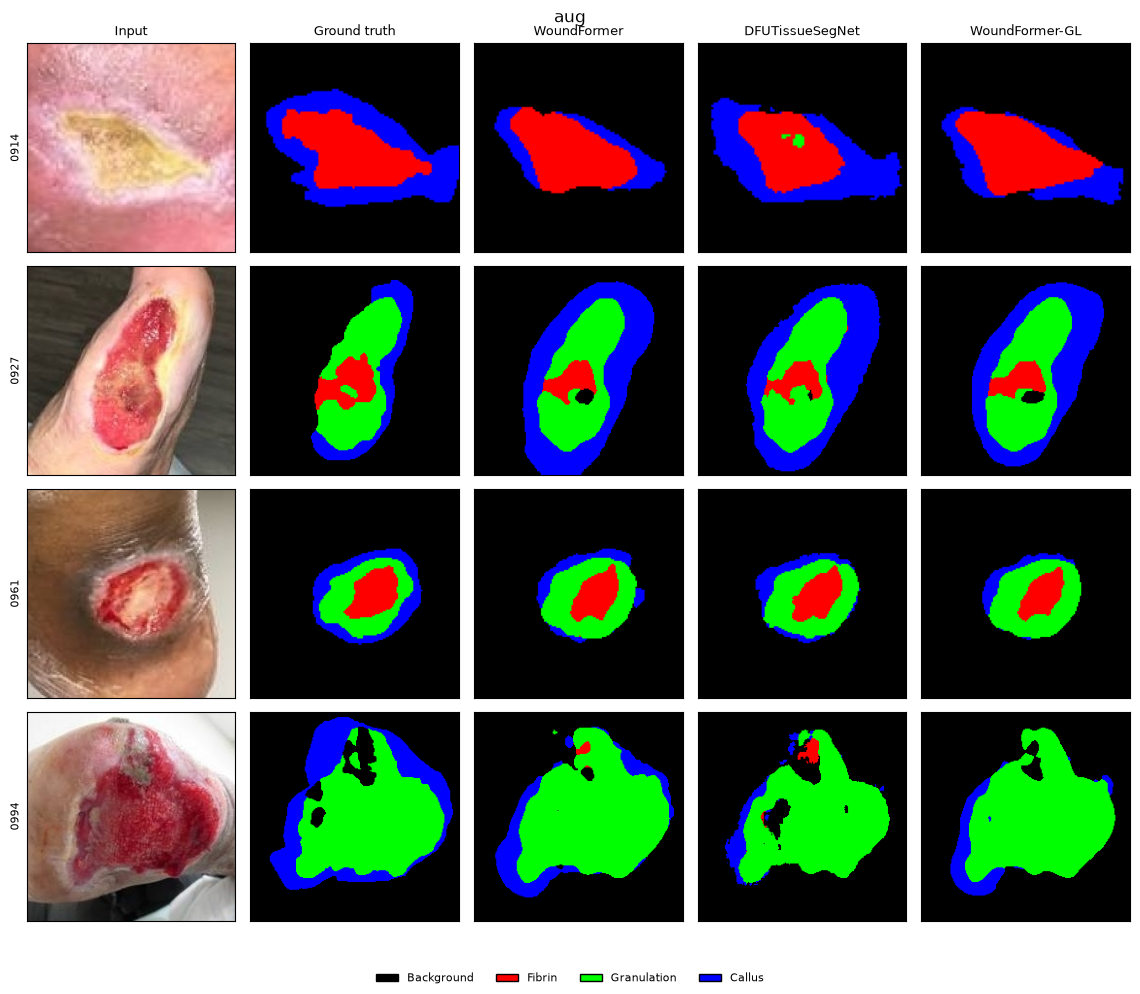

In [8]:
IMAGES = ['0914', '0927', '0961', '0994']
labels = {'woundformer': 'WoundFormer', 'dfutissuesegnet': 'DFUTissueSegNet', 'woundformer_gl': 'WoundFormer-GL'}
for setting in SETTINGS:
    ms = [m for m in MODELS if (run_dir(m, setting, SEED) / 'test_pred').exists()]
    if ms:
        fig = visualize.qualitative([str(run_dir(m, setting, SEED)) for m in ms], [labels[m] for m in ms],
                                    DATA_ROOT, IMAGES, out=f'figures/qualitative_{setting}_s{SEED}.png')
        fig.suptitle(setting, y=1.0)
        plt.show()

## Per-class comparison with the paper

saved figures/bars_noaug_s0.png


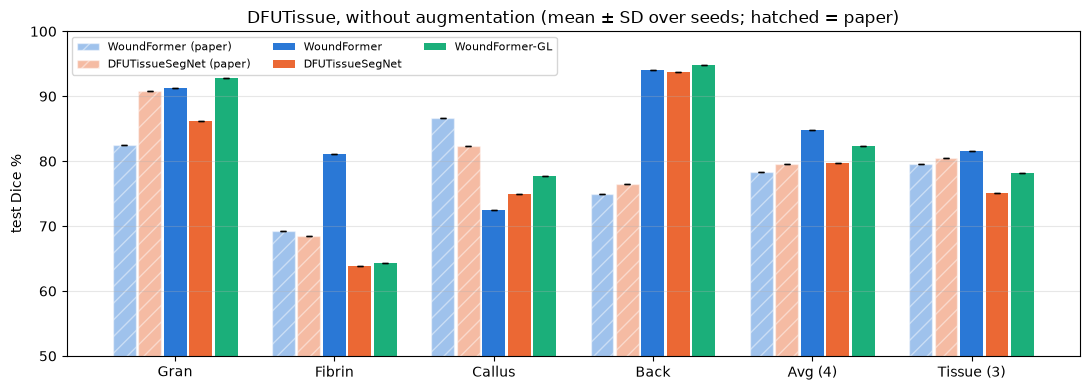

saved figures/bars_aug_s0.png


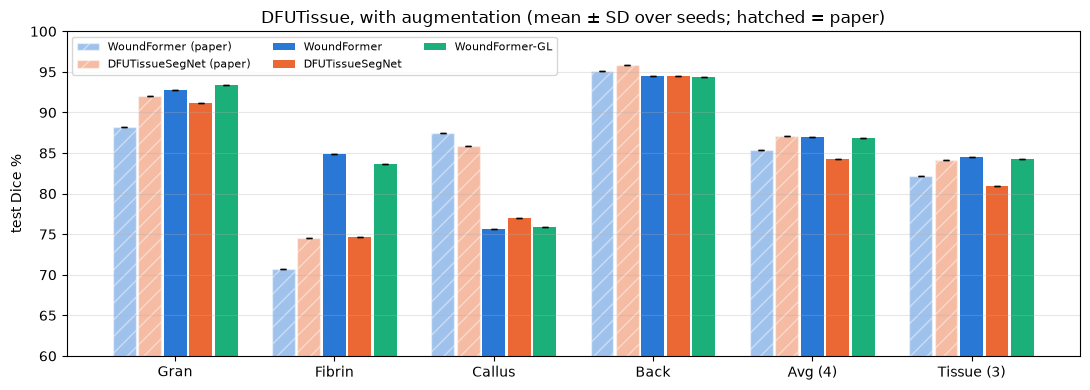

In [9]:
for setting in SETTINGS:
    fig = visualize.bars(RUNS_ROOT, setting, [SEED], MODELS, out=f'figures/bars_{setting}_s{SEED}.png')
    plt.show()